# AA 279B HW 6 Prob 2

## Imports

In [318]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [319]:
import matlab.engine
from matlab.engine import MatlabEngine

# 1. Start the MATLAB process in the background
print("Starting MATLAB engine...")
eng: MatlabEngine = matlab.engine.start_matlab()

Starting MATLAB engine...


## Setup

In [320]:
import os
import sys

sys.path.insert(0, os.path.abspath('..'))

In [384]:
import numpy as np
import pandas as pd
from numpy.linalg import norm
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

from constants import DAY_TO_SEC, RAD_TO_SIDEREAL_HOUR, RAD_TO_DEG, MIN_TO_SEC, R_EARTH, MU_EARTH, R_SUN, C_LIGHT
from orbital import calc_theta_g, rv_HCI, ECI_from_HCI, cartesian_from_lla, lla_from_cartesian, calc_PCI_from_PCPF, calc_PCPF_from_PCI, spreading_loss
from dynamics import two_body
from spacetime import greg_to_jd
from angle import wrap_to_2pi, wrap_to_pi, angle_between, dcm_x, dcm_z
from utils import unit
from plotting import plot_3d, plot_earth_departure

In [322]:
MU_SUN = 1.3271244004193938e11  # km3/s2
ECLIPTIC_ANGLE = 23.45  # DEG
W_EARTH = 0.0000729211585530  # rad/s

In [323]:
# Dates
t_earth_dep_jd = greg_to_jd(2026, 10, 19, 19, 41, 3)
t_mars_arr_jd = greg_to_jd(2027, 8, 15, 0, 0, 0)
t_trans_jd = (t_mars_arr_jd - t_earth_dep_jd) * DAY_TO_SEC

# Greenwich angle
t_ref_jd = greg_to_jd(2026, 1, 1, 0, 0, 0) 
theta_ref = 6.7107222 / RAD_TO_SIDEREAL_HOUR

# Launch site
launch_lat_deg = 30.2333
launch_lon_deg = 130.9776


### Part a

In [324]:
r_earth_dep_hci, v_earth_dep_hci = rv_HCI(3, t_earth_dep_jd, eng)
r_mars_arr_hci, v_mars_arr_hci = rv_HCI(4, t_mars_arr_jd, eng)

def calc_transfer(r1_hci: np.ndarray, r2_hci: np.ndarray, t_trans: float):
    result = eng.AA279lambert_curtis(MU_SUN, r1_hci, r2_hci, "pro", "ignored", t_trans, nargout=2)
    
    # heliocentric asymptotic arrival and departure velocity vectors
    v1_hci, v2_hci = np.array(result[0]).reshape((3,)), np.array(result[1]).reshape((3,))

    return v1_hci, v2_hci

v_dep_hci, v_arr_hci = calc_transfer(r_earth_dep_hci, r_mars_arr_hci, t_trans_jd)

print(f"Heliocentric Earth Departure Velocity:\n\t{v_dep_hci} ({norm(v_dep_hci):.3f})[km/s]")
print(f"Heliocentric Mars Arrival Velocity:\n\t{v_arr_hci} ({norm(v_arr_hci):.3f})[km/s]")

Heliocentric Earth Departure Velocity:
	[-15.79181262  28.89963785   0.07344544] (32.933)[km/s]
Heliocentric Mars Arrival Velocity:
	[ 17.17778138 -12.41740268  -0.04199491] (21.196)[km/s]


### Part b

In [325]:
# Earth-centric
dcm_hci_wrt_eci = dcm_x(ECLIPTIC_ANGLE/RAD_TO_DEG)
v_dep_eci = dcm_hci_wrt_eci.T @ (v_dep_hci - v_earth_dep_hci)
print(f"Earth-centric Departure Velocity:\n\t{v_dep_eci} ({norm(v_dep_eci):.3f})[km/s]")

Earth-centric Departure Velocity:
	[-2.21913846  2.03627556  0.96510994] (3.163)[km/s]


### Part c

In [326]:
# C3, RLA, DLA
C3 = norm(v_dep_eci)**2
print(f"Earth C3:\n\t{C3:.3f} [km2/s2]")

# decl = np.arctan2(v_dep_eci[2], norm(v_dep_eci[0:2]))  # also works
rla = wrap_to_2pi(np.arctan2(v_dep_eci[1], v_dep_eci[0]))
print(f"Ascension:\n\t{rla * RAD_TO_DEG:.3f} [deg]")

dla = wrap_to_pi(np.arcsin(v_dep_eci[2] / norm(v_dep_eci)))
print(f"Declination:\n\t{dla * RAD_TO_DEG:.3f} [deg]")

Earth C3:
	10.002 [km2/s2]
Ascension:
	137.461 [deg]
Declination:
	17.768 [deg]


### Part d

In [327]:
def launch_azimuths(rla, dla, lat_rad, lon_rad, epoch_s):
    alpha_launch = wrap_to_2pi(lon_rad + calc_theta_g(epoch_s, theta_ref, t_ref_jd * DAY_TO_SEC, W_EARTH))
    print(f"Launch site ascension: {alpha_launch * RAD_TO_DEG:.3f}º")

    d_alpha = rla - alpha_launch
    tan_beta = np.sin(d_alpha) / (
        np.cos(lat_rad)*np.tan(dla) - np.sin(lat_rad)*np.cos(d_alpha)
    )

    betas = sorted((
        wrap_to_2pi(np.arctan(tan_beta)),
        wrap_to_2pi(np.arctan(tan_beta) + np.pi)
    ))

    return betas, alpha_launch

betas, alpha_launch = launch_azimuths(rla, dla, launch_lat_deg/RAD_TO_DEG, launch_lon_deg/RAD_TO_DEG, t_earth_dep_jd * DAY_TO_SEC)
print(f"Solution 1: {betas[0] * RAD_TO_DEG:.3f}º")
print(f"Solution 2: {betas[1] * RAD_TO_DEG:.3f}º")

Launch site ascension: 94.533º
Solution 1: 97.679º
Solution 2: 277.679º


In [328]:
# Using geometry (and starting altitude of 300 km)
def rv_toward_vinf(lat, alpha, v_inf):
    r0 = cartesian_from_lla(lat, alpha, 
                        alt_km=300, deg=False)
    east_hat = unit(np.cross([0,0,1], r0))
    north_hat = unit(np.cross(east_hat, -r0))
    beta_hat = unit(v_inf - np.dot(v_inf, unit(r0)) * unit(r0))
    v0 = beta_hat * np.sqrt(MU_EARTH / norm(r0))

    return r0, v0, beta_hat, east_hat, north_hat

r0, v0, beta_hat, east_hat, north_hat = rv_toward_vinf(launch_lat_deg/RAD_TO_DEG, alpha_launch, v_dep_eci)

print(f"Verifying beta angle with geometry: {angle_between(beta_hat, north_hat)*RAD_TO_DEG:.3f}")

Verifying beta angle with geometry: 97.679


In [329]:
new_time_s = greg_to_jd(2026, 10, 19, 21, 0, 0) * DAY_TO_SEC
betas_delay, alpha_launch_delay = launch_azimuths(rla, dla, launch_lat_deg/RAD_TO_DEG, launch_lon_deg/RAD_TO_DEG, new_time_s)

print(f"Solution 1: {betas_delay[0] * RAD_TO_DEG:.3f}º")
print(f"Solution 2: {betas_delay[1] * RAD_TO_DEG:.3f}º")

Launch site ascension: 114.324º
Solution 1: 115.352º
Solution 2: 295.352º


### Part e

- According to the wikipedia page for $C_3$ (https://en.wikipedia.org/wiki/Characteristic_energy), the MAVEN spacecraft departed for Mars with about $12.2 \text{ km}^2/\text{s}^2$ of $C_3$, which is in the range of the $C_3$ we have.

- The DLA is less than the geocentric latitude, so it does not need to expend extra fuel to launch into a high-inclination orbit.

- The launch azimuth (for the non-delayed launch) appears to be the same as what is on the graph (see ground track plot below)

<!-- 
For the actual 19:41:03 UTC launch time, does your estimated value of C3 fall
within a reasonable range for Earth-to-Mars missions? Is your estimated DLA less than
or equal to the geocentric latitude of the launch site, indicating that JAXA avoided any
“launch penalty” associated with launching to high-inclination orbits? How does your
estimated launch azimuth compare with the planned easterly groundtrack shown on
pg. 10 of the JAXA MMX launch plan?  -->

In [330]:
flight_plan = pd.DataFrame(
    columns=[
            "event",
            "time_hms",  # (hours, minutes, seconds)
            "time_s",
            "altitude_km",
            "inertial_speed_km_s",
        ],
    data=[
        ("Liftoff",                      (0,  0,  0),    0,   0,  0.4),
        ("SRB-3 first pair separation",  (0,  1, 56),  116,  59,  2.1),
        ("SRB-3 second pair separation", (0,  1, 58),  118,  61,  2.1),
        ("Payload fairing separation",   (0,  3, 17),  197, 131,  3.3),
        ("First-stage cutoff (MECO)",    (0,  4, 52),  292, 208,  6.2),
        ("Stage separation",             (0,  4, 59),  299, 214,  6.2),
        ("Second-stage ignition 1",      (0,  5, 12),  312, 224,  6.2),
        ("Second-stage cutoff 1",        (0, 10, 40),  640, 329,  7.7),
        ("Second-stage ignition 2",      (1,  3, 57), 3837, 322,  7.7),
        ("Second-stage cutoff 2",        (1, 10, 21), 4221, 497, 11.2),
        ("MMX separation",               (1, 11, 12), 4272, 592, 11.2),
    ],
    
)

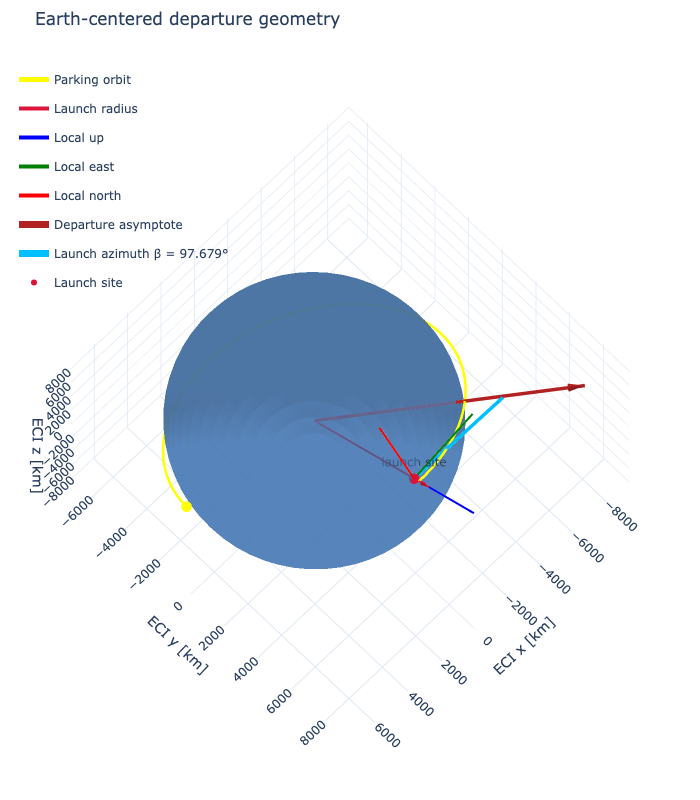

In [331]:
# No delay
t_arr = np.linspace(0, 65 * MIN_TO_SEC, 100000)
result = solve_ivp(lambda t,s: two_body(s), (t_arr[0], t_arr[-1]), np.concatenate((r0, v0)), t_eval=t_arr, rtol=1e-9,atol=1e-12)

fig = plot_earth_departure(
    v_dep_eci, launch_lat_deg, launch_lon_deg,
    alpha_launch=alpha_launch,
    traces=result.y[:3].T, t_arrs=result.t, labels="Parking orbit",

    show=False,
    elev=70
)
fig.show(renderer="png")


Text(0.5, 1.0, 'Ground track over 65.0 min')

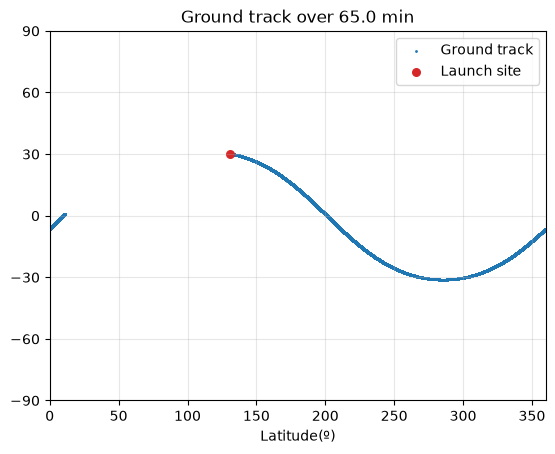

In [332]:
theta_g_start = calc_theta_g(
    t_earth_dep_jd * DAY_TO_SEC, theta_ref, t_ref_jd * DAY_TO_SEC, W_EARTH
)
r_pcpf = np.array([
    dcm_z(theta_g_start + W_EARTH * dt) @ r
    for dt, r in zip(result.t, result.y[:3].T)
])

lla = np.array([
        lla_from_cartesian(r) for r in r_pcpf
    ])

fig,ax = plt.subplots()
ax.scatter(lla[:,1] % 360, lla[:,0], s=1, label="Ground track")
(MultipleLocator(30))
ax.yaxis.set_major_locator(MultipleLocator(30))

ax.set_xlim(0, 360)
ax.set_xlabel("Longitude (º)")
ax.set_xlabel("Latitude(º)")
ax.scatter(lla[0,1], lla[0,0], label="Launch site", marker="o", color="tab:red", s=30)
ax.set_ylim(-90, 90)
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_title(f"Ground track over {t_arr[-1] / MIN_TO_SEC} min")

### Part f

In [333]:
# Earth-centric
v_arr_mars = v_arr_hci - v_mars_arr_hci
print(f"Mars-centric Arrival Velocity:\n\t{norm(v_arr_mars):.3f} km/s")

Mars-centric Arrival Velocity:
	2.783 km/s


### Part g

In [ ]:
coast_state0 = np.concatenate((r_earth_dep_hci, v_dep_hci))

t_coast_arr = np.linspace(t_earth_dep_jd, t_mars_arr_jd, 10000) * DAY_TO_SEC
assert (t_coast_arr[1] - t_coast_arr[0]) < 0.1*DAY_TO_SEC

sat_coast = solve_ivp(lambda _,s: two_body(s, MU_SUN), (t_coast_arr[0], t_coast_arr[-1]), coast_state0, t_eval=t_coast_arr, rtol=1e-9,atol=1e-12)

r_sat_coast_hci = sat_coast.y.T[:,:3]

### Part h

In [381]:
earth_state0 = np.concatenate((r_earth_dep_hci, v_earth_dep_hci))
mars_state0 = np.array(rv_HCI(4, t_earth_dep_jd, eng)).ravel()

earth_coast = solve_ivp(lambda _,s: two_body(s, MU_SUN), (t_coast_arr[0], t_coast_arr[-1]), earth_state0, t_eval=t_coast_arr, rtol=1e-9,atol=1e-12)
mars_coast = solve_ivp(lambda _,s: two_body(s, MU_SUN), (t_coast_arr[0], t_coast_arr[-1]), mars_state0, t_eval=t_coast_arr, rtol=1e-9,atol=1e-12)

r_earth_coast_hci = earth_coast.y.T[:,:3]
r_mars_coast_hci = mars_coast.y.T[:,:3]

In [386]:
sep_deg = np.array([angle_between(-r_earth, r_sat-r_earth) for r_earth,r_sat in zip(r_earth_coast_hci, r_sat_coast_hci)]) * RAD_TO_DEG
spe_deg = np.array([angle_between(-r_sat, r_earth-r_sat) for r_sat,r_earth in zip(r_sat_coast_hci, r_earth_coast_hci)]) * RAD_TO_DEG
smp_deg = np.array([angle_between(-r_mars, r_sat-r_mars) for r_sat,r_mars in zip(r_sat_coast_hci, r_mars_coast_hci)]) * RAD_TO_DEG

dist_sat_earth = norm(r_sat_coast_hci-r_earth_coast_hci, axis=1)
t_one_way_min = dist_sat_earth / C_LIGHT / MIN_TO_SEC

t_earth_received_jd = t_coast_arr + (t_one_way_min*MIN_TO_SEC / DAY_TO_SEC)

spreading_loss = [spreading_loss(norm(r)) for r in dist_sat_earth]

### Part i

In [ ]:
elapsed_days = (t_coast_arr - t_coast_arr[0]) / DAY_TO_SEC

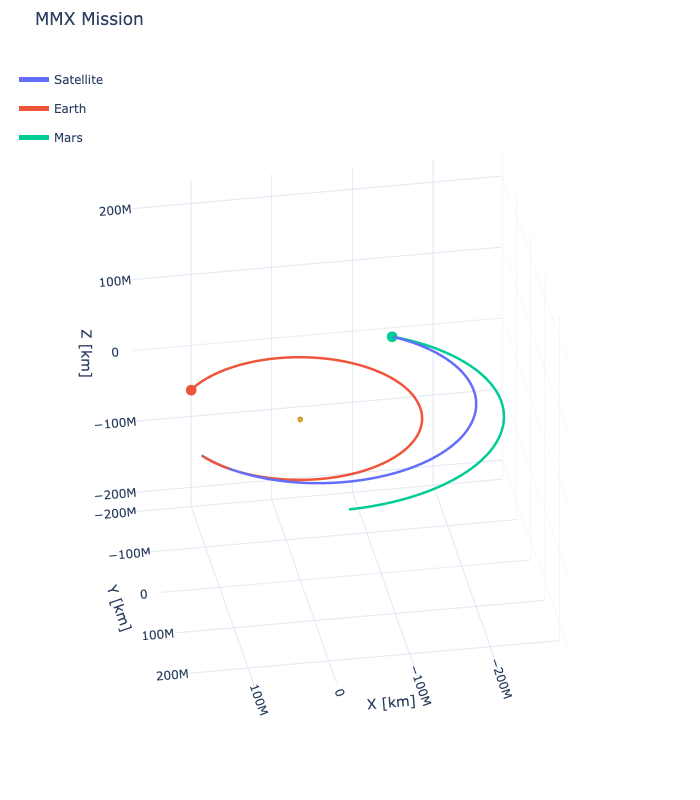

In [ ]:
fig = plot_3d([r_sat_coast_hci, r_earth_coast_hci, r_mars_coast_hci], t_coast_arr, 
              labels=["Satellite", "Earth", "Mars"], bodies={"name": "Sun", "radius": R_SUN*5, "color": "goldenrod"}, title="MMX Mission", show=False,
              azim=80, elev=30, camera_distance=3)
fig.show(renderer="png")

### Part h

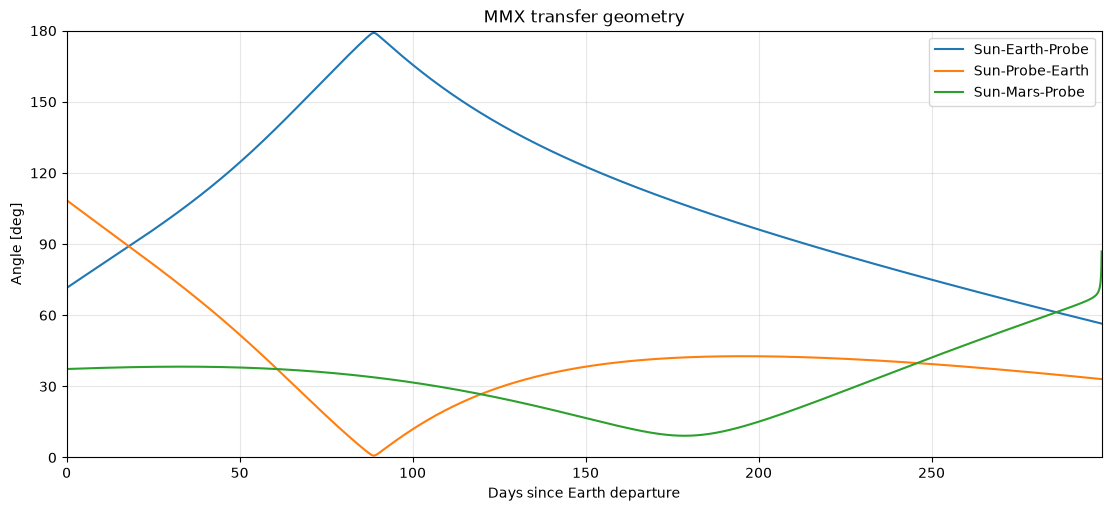

In [ ]:

fig_angles, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
for angles, name, color in zip(
    (sep_deg, spe_deg, smp_deg),
    ("Sun-Earth-Probe", "Sun-Probe-Earth", "Sun-Mars-Probe"),
    ("tab:blue", "tab:orange", "tab:green"),
):
    ax.plot(elapsed_days, angles, label=name, color=color, linewidth=1.5)

ax.set(xlabel="Days since Earth departure", ylabel="Angle [deg]",
       title="MMX transfer geometry", ylim=(0, 180),
       xlim=(elapsed_days[0], elapsed_days[-1]))
ax.set_yticks([0, 30, 60, 90, 120, 150, 180])
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()



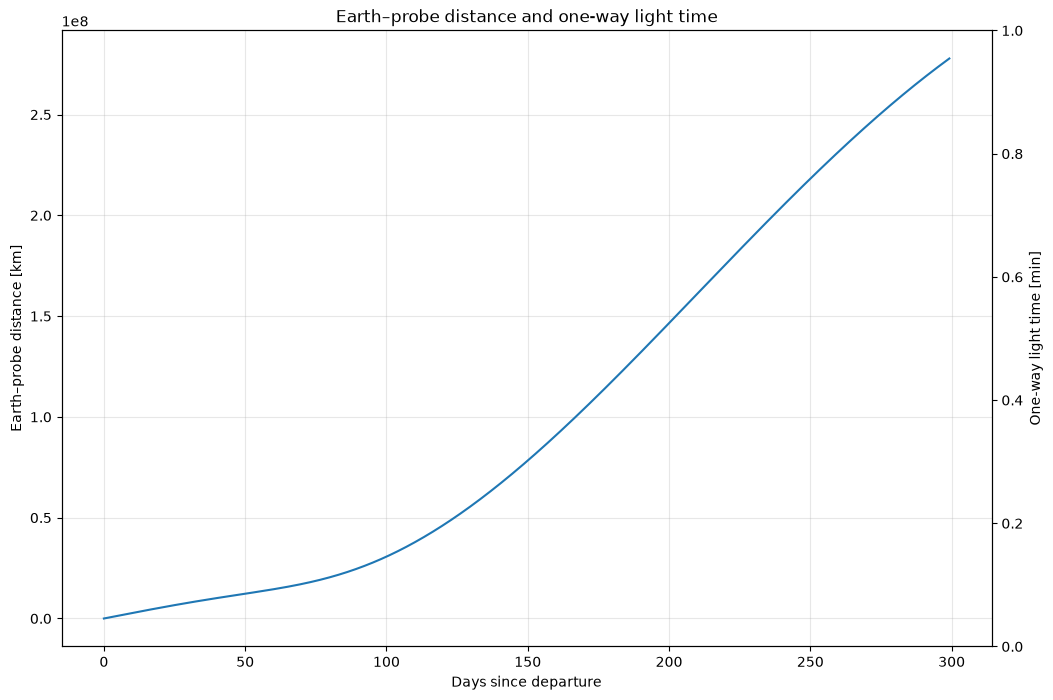

In [ ]:


fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(elapsed_days, dist_sat_earth, color="tab:blue")
ax.set(xlabel="Days since departure", ylabel="Earth–probe distance [km]",
       title="Earth–probe distance and one-way light time")

ax.grid(True, alpha=0.3)
ax2 = ax.twinx()
ax2.set_ylabel("One-way light time [min]")

plt.show()


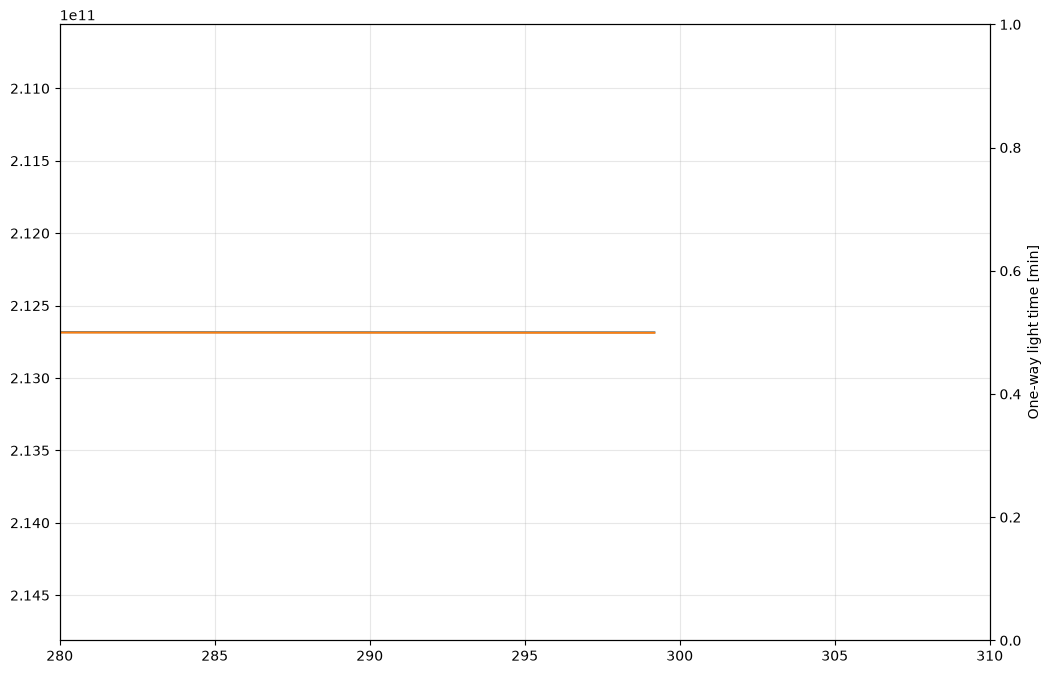

In [ ]:

fig, ax = plt.subplots(figsize=(12, 8))
ax.plot(elapsed_days, t_earth_received_jd, color="tab:blue")
ax.plot(elapsed_days, t_earth_dep_jd + t_coast_arr , color="tab:orange")
# ax.set(xlabel="Days since departure", ylabel="Earth–probe distance [km]",
#        title="Earth–probe distance and one-way light time")
plt.xlim(280, 310)
plt.ylim(t_earth_received_jd[-1]*1.01, t_earth_received_jd[-1]*.99)

ax.grid(True, alpha=0.3)
ax2 = ax.twinx()
ax2.set_ylabel("One-way light time [min]")

plt.show()


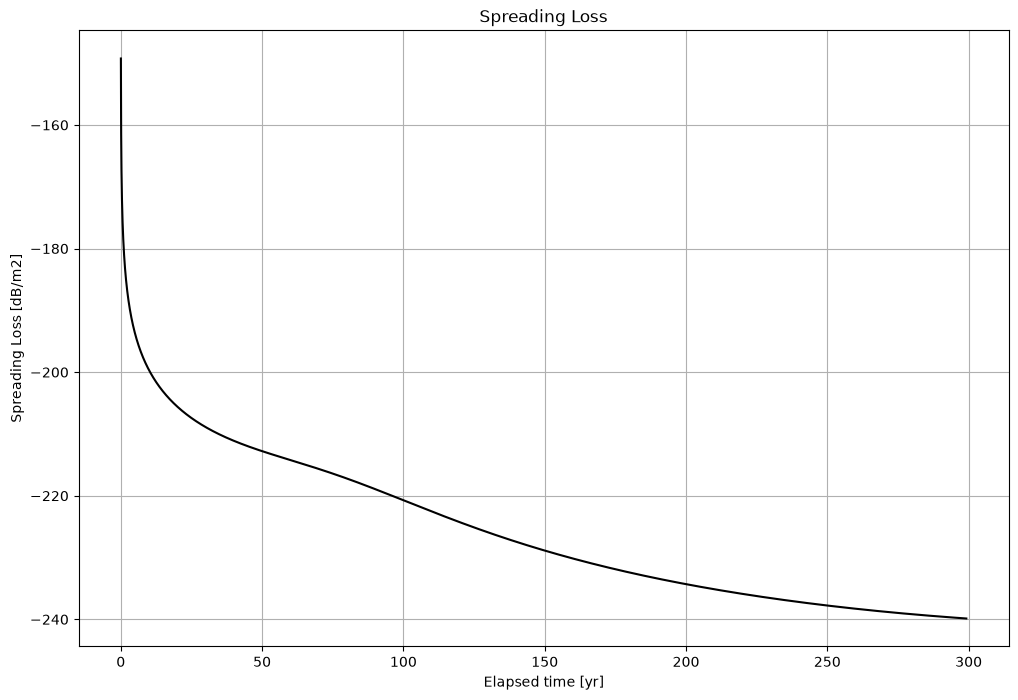

In [ ]:


plt.figure(figsize=(12,8))
plt.title("Spreading Loss")

# Plotted thing
plt.plot(elapsed_days, losses, color="k")

plt.xlabel("Elapsed time [yr]")
plt.ylabel("Spreading Loss [dB/m2]")
plt.grid(True)
plt.show()

More:
- max data rate given distance
- transmission time
- dsn visibility
- carrier freq (doppler)

### Part i